# 04 · From profiles to household presets

Notebook 03 produced **profiles**: for every item, the most common decision among a group of similar households. A
profile is 6,272 decisions, which nobody can read or edit. This notebook turns each profile into a **preset**: a short,
list of household rules that the app can show, edit and compile into PPD policies.

Steps:

1. **Fill the gaps.** Items where a profile has less than 80% agreement still need a decision, because the household
   is never asked (CableLabs guidance). A `FALLBACK` setting chooses how (notebook 03 compared the options).
2. **Compress** the 6,272 decisions into rules with a decision tree over the five fields. Each leaf of the tree is one
   rule: *"for these data types, purposes, … → deny / allow / allow if …"*. The leaves don't overlap, so exactly one
   rule applies to any item. **How many rules** is measured, not fixed: the earlier limit of 15 was our own choice for
   readability (capstone plan §5.1), not a requirement of PPD or of Daniel, and it costs accuracy.
3. **Measure** what compression costs: fidelity to the profile, on all items and on the 52 real-device items, and how
   often the rules match each household's own decisions.
4. **Name** each preset from what sets it apart, and save the presets for notebooks 05 and 07.

**Rule format.** Each rule has a `scope` (lists of core terms per field; a missing field means "any") and an effect,
like the app's rules (`shared/types.ts`). PPD rules are allow or deny (protocol-04 §7.11); an *allow if …* rule is an
`allow` that carries a qualifier, which the compiler sends as `constraints` (§7.12). The app's rules cannot express
that condition yet: it needs a small extension (a `condition` on an allow rule).

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
DECISIONS = json.loads((ROOT / "decisions.json").read_text())   # team decisions, shared by notebooks 03-05
TEAM_K = DECISIONS["presets_k"]
items = pd.read_csv(DATA / "items.csv")
H = pd.read_csv(DATA / "households.csv")
D = np.load(DATA / "decisions.npy")
labels = pd.read_csv(DATA / "profiles" / "labels.csv")
FIELDS = ["data_type", "purpose", "action", "source", "handling_context"]
TERMS = {f: sorted(items[f].unique()) for f in FIELDS}
CODES = {0: "deny", 1: "allow", 2: "allow if not kept", 3: "allow if in-home only", 4: "allow if on-device only"}
CONDITION = {2: "retention=ppd:ephemeral", 3: "processing_boundary=ppd:inHomeOnly", 4: "processing_boundary=ppd:onDeviceOnly"}
real = items.in_corpus.to_numpy()
home = ~items.leaves_home.to_numpy()
short = lambda term: term.split(":", 1)[1]
CANDIDATES = [int(c[1:]) for c in labels.columns if c.startswith("k")]
assert TEAM_K in CANDIDATES, "decisions.json names a k that notebook 03 did not cluster"
print("profiles available for k =", CANDIDATES, "| team k =", TEAM_K)

profiles available for k = [2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24] | team k = 4


## Settings

In [2]:
MAX_RULES = None                    # None = choose per k at the knee of the sweep below; a number fixes it (e.g. 15 for readability)
RULE_COUNTS = [5, 10, 15, 20, 30, 40, 60, 80, 120, 160]   # rule counts to try
THRESHOLD = 0.8
FALLBACK = "majority"   # for items below THRESHOLD: "majority" | "home_away" | "strict"
# How much each item counts when fitting the rules: real-device flows most, implausible combinations least.
WEIGHT_REAL, WEIGHT_PLAUSIBLE, WEIGHT_IMPLAUSIBLE = 5.0, 1.0, 0.1
weights = np.where(real, WEIGHT_REAL, np.where(items.plausible, WEIGHT_PLAUSIBLE, WEIGHT_IMPLAUSIBLE))

## Step 1 · Fill the gaps

- **majority**: use the profile's most common decision anyway. Highest accuracy in notebook 03.
- **home_away**: allow if the flow stays in the home, deny if it leaves. Cautious; like CableLabs' bulb firmware.
- **strict**: deny.

This is a privacy-versus-accuracy choice, not only a statistic: *majority* follows what similar households chose;
the cautious options deny some flows those households would have allowed.

In [3]:
def profile_decisions(k, fallback=FALLBACK):
    p = np.load(DATA / "profiles" / f"profiles_k{k}.npz")
    majority, agreement = p["majority"], p["agreement"].astype(np.float32)
    if fallback == "majority":
        return majority, agreement
    fill = np.where(home, 1, 0) if fallback == "home_away" else np.zeros(len(items), dtype=np.uint8)
    return np.where(agreement >= THRESHOLD, majority, fill[None, :]).astype(np.uint8), agreement

## Step 2 · Compress into rules

A decision tree over the five fields (one yes/no feature per core term) predicts the profile's decision for each item,
with at most a given number of leaves (the rule count). Every condition on the path to a leaf restricts one field ("data type is content" or
"handling context is not the household"), so each leaf is a block of combinations: a list of allowed terms per field.
That is exactly a rule scope.

**Keeping rules valid.** A processing-boundary condition (*in-home only*, *on-device only*) is defined only for
**use** and **inference** (taxonomy-05 §6.7.2; protocol-04 §7.12), and a qualifier outside its defined applicability
is invalid (§6.7). A leaf can mix those with collection or transfer items; such a rule is split into the use/inference
part (keeping the condition) and the rest (with that part's own most common decision). If splitting pushes a preset
over the rule count, the tree is refitted with fewer leaves.

In [4]:
X = pd.get_dummies(items[FIELDS]).astype(np.float32)
FEATURE = [c.split("_ppd:")[0] and (c[: c.index("_ppd:")], "ppd:" + c.split("_ppd:")[1]) for c in X.columns]   # (field, term)
X = X.to_numpy()

BOUNDARY_ACTIONS = {"ppd:use", "ppd:inference"}

def block(allowed):
    inside = np.ones(len(items), dtype=bool)
    for f, terms in allowed.items():
        inside &= items[f].isin(terms).to_numpy()
    return inside

def make_valid(rules, decisions):
    # Split boundary-condition rules that also cover collection or transfer.
    out = []
    for r in rules:
        other = set(r["allowed"]["action"]) - BOUNDARY_ACTIONS
        if r["decision"] in (3, 4) and other:
            keep = {**r["allowed"], "action": sorted(set(r["allowed"]["action"]) & BOUNDARY_ACTIONS)}
            rest = {**r["allowed"], "action": sorted(other)}
            if keep["action"]:
                out.append({"allowed": keep, "decision": r["decision"]})
            rest_decisions = decisions[block(rest)]
            out.append({"allowed": rest, "decision": int(np.bincount(rest_decisions, minlength=5).argmax())})
        else:
            out.append(r)
    return out

def compress(decisions, max_rules):
    # Fewest changes: start with max_rules leaves; refit with fewer if validity splits push past max_rules.
    for leaves in range(max_rules, 1, -1):
        rules = make_valid(fit_rules(decisions, leaves), decisions)
        if len(rules) <= max_rules:
            break
    predicted = np.zeros(len(items), dtype=np.uint8)
    for r in rules:
        inside = block(r["allowed"])
        predicted[inside] = r["decision"]
        r["items"] = int(inside.sum())
        r["fidelity"] = float((r["decision"] == decisions[inside]).mean())
    return rules, predicted

def fit_rules(decisions, leaves):
    # Fit the tree and turn each leaf into a rule: {scope, decision}.
    tree = DecisionTreeClassifier(max_leaf_nodes=leaves, random_state=0).fit(X, decisions, sample_weight=weights)
    t = tree.tree_
    rules = []
    def walk(node, allowed):
        if t.children_left[node] == -1:   # a leaf
            decision = int(tree.classes_[t.value[node][0].argmax()])
            rules.append({"allowed": {f: sorted(v) for f, v in allowed.items()}, "decision": decision})
            return
        field, term = FEATURE[t.feature[node]]
        no = dict(allowed); no[field] = allowed[field] - {term}         # feature <= 0.5: the term is not used
        yes = dict(allowed); yes[field] = allowed[field] & {term}       # feature > 0.5: the term is used
        walk(t.children_left[node], no); walk(t.children_right[node], yes)
    walk(0, {f: set(TERMS[f]) for f in FIELDS})
    return rules

### Rules in plain words

A field restricted to most of its terms reads better as "all except …".

In [5]:
FIELD_WORDS = {"data_type": "data", "purpose": "for", "action": "when", "source": "from", "handling_context": "handled by"}
def describe_terms(field, terms):
    everything = TERMS[field]
    if len(terms) == len(everything):
        return None
    missing = [t for t in everything if t not in terms]
    if len(missing) < len(terms):
        return f"{FIELD_WORDS[field]} anything except {', '.join(map(short, missing))}"
    return f"{FIELD_WORDS[field]} {', '.join(map(short, terms))}"

def rule_text(rule):
    parts = [p for f in FIELDS if (p := describe_terms(f, rule["allowed"][f]))]
    return f"{CODES[rule['decision']].upper()}: " + ("; ".join(parts) if parts else "everything else")

## How many rules?

For every candidate k, the presets are built with each rule count in `RULE_COUNTS` and measured: how often their
rules match each household's own decisions (the profile itself is the ceiling) and how faithful they are to the profile.
More rules always fit better; the question is where more stop paying. As for k and depth, the choice is the **knee**
of household match against the number of rules (Kneedle; Satopää et al. 2011), per k. Rule count does not change
what the app sends to devices (the compiler sends one atomic rule per declared flow); it changes how closely the
household's rules follow its profile, and how long the rules page is.

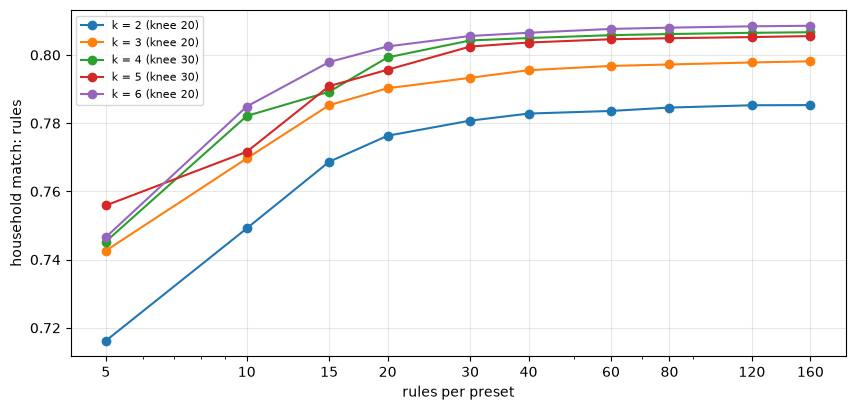

rules per preset, chosen per k: {2: 20, 3: 20, 4: 30, 5: 30, 6: 20, 8: 20, 10: 30, 12: 30, 16: 30, 20: 30, 24: 20}


,household match: rules,household match: profile,fidelity to profile,share of the profile's match kept
rules,,,,
5,0.7453,0.8068,0.8405,0.0000
10,0.7821,0.8068,0.9084,0.5992
15,0.7892,0.8068,0.9336,0.7145
20,0.7993,0.8068,0.9533,0.8786
30,0.8043,0.8068,0.9717,0.9592
40,0.8050,0.8068,0.9783,0.9708
60,0.8058,0.8068,0.9848,0.9845
80,0.8061,0.8068,0.9885,0.9899
120,0.8065,0.8068,0.9942,0.9958


In [6]:
def household_accuracy(k, per_item):
    lab = labels[f"k{k}"].to_numpy()
    return float(np.mean([(D[lab == c] == per_item[c]).mean() for c in range(k)]))

def knee(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    return int(x[np.argmax((y - y.min()) / max(y.max() - y.min(), 1e-12) - (x - x.min()) / (x.max() - x.min()))])

sweep = []
for k in CANDIDATES:
    decisions, _ = profile_decisions(k)
    for n_rules in RULE_COUNTS:
        per_item = np.stack([compress(decisions[c], n_rules)[1] for c in range(k)])
        sweep.append({"k": k, "rules": n_rules, "household match: rules": household_accuracy(k, per_item),
                      "household match: profile": household_accuracy(k, decisions),
                      "fidelity to profile": float((per_item == decisions).mean())})
sweep = pd.DataFrame(sweep)
sweep["share of the profile's match kept"] = 1 - (sweep["household match: profile"] - sweep["household match: rules"]) / (
    sweep["household match: profile"] - sweep.groupby("k")["household match: rules"].transform("min"))
RULES_BY_K = {k: (MAX_RULES or knee(g.rules, g["household match: rules"])) for k, g in sweep.groupby("k")}

fig, ax = plt.subplots(figsize=(10, 4.5))
for k, g in sweep.groupby("k"):
    if k <= 6 or k == TEAM_K:
        ax.plot(g.rules, g["household match: rules"], marker="o", label=f"k = {k} (knee {RULES_BY_K[k]})")
ax.set_xscale("log"); ax.set_xticks(RULE_COUNTS); ax.set_xticklabels(RULE_COUNTS)
ax.set_xlabel("rules per preset"); ax.set_ylabel("household match: rules"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()
print("rules per preset, chosen per k:", RULES_BY_K)
sweep[sweep.k == TEAM_K].set_index("rules").drop(columns="k").round(4)

## Step 3 · Build the presets for every candidate k and measure them

In [7]:
results, presets_by_k = [], {}
for k in CANDIDATES:
    decisions, agreement = profile_decisions(k)
    compressed = [compress(decisions[c], RULES_BY_K[k]) for c in range(k)]
    per_item = np.stack([pred for _, pred in compressed])
    presets_by_k[k] = (decisions, agreement, compressed, per_item)
    results.append({
        "k": k,
        "rules allowed": RULES_BY_K[k], "rules per preset (max)": max(len(r) for r, _ in compressed),
        "fidelity to profile": float((per_item == decisions).mean()),
        "fidelity, real-device items": float((per_item[:, real] == decisions[:, real]).mean()),
        "household match: profile": household_accuracy(k, decisions),
        "household match: rules": household_accuracy(k, per_item),
    })
pd.DataFrame(results).set_index("k").round(3)

,rules allowed,rules per preset (max),fidelity to profile,"fidelity, real-device items",household match: profile,household match: rules
k,,,,,,
2,20,20,0.935,0.990,0.786,0.776
3,20,20,0.947,0.981,0.798,0.790
4,30,30,0.972,0.986,0.807,0.804
5,30,30,0.967,0.992,0.806,0.802
6,20,20,0.953,0.990,0.809,0.803
8,20,20,0.949,0.978,0.809,0.801
10,30,30,0.967,0.996,0.811,0.808
12,30,30,0.965,0.997,0.813,0.809
16,30,30,0.963,0.996,0.816,0.812


Compression costs some household match (the rules are coarser than the profile); the rule count at the knee keeps most
of it. Real-device flows are fitted more closely because they carry more weight.

### Fallbacks, compared after compression (the team's k)

In [8]:
rows = {}
for fb in ["majority", "home_away", "strict"]:
    decisions, _ = profile_decisions(TEAM_K, fb)
    per_item = np.stack([compress(decisions[c], RULES_BY_K[TEAM_K])[1] for c in range(TEAM_K)])
    rows[fb] = {"household match": household_accuracy(TEAM_K, per_item),
                "denied share": float((per_item == 0).mean()),
                "real-device flows denied": float((per_item[:, real] == 0).mean())}
pd.DataFrame(rows).T.round(3)

,household match,denied share,real-device flows denied
majority,0.804,0.489,0.269
home_away,0.733,0.613,0.356
strict,0.732,0.693,0.385


## Step 4 · Name the presets

A name is built from what sets each preset apart from all households: the purpose, handling context and data type where it
is most and least accepting. These are working names; people should rename them before they reach the app.

In [9]:
ordinal = np.array([0.0, 1.0, 0.5, 0.5, 0.5])
overall = ordinal[D].mean(axis=0)
def name_for(per_item):
    acc = ordinal[per_item]
    deltas = {}
    for f in ["purpose", "handling_context", "data_type"]:
        g = pd.Series(acc - overall).groupby(items[f].map(short)).mean()
        deltas.update({f"{f}:{k}": v for k, v in g.items()})
    s = pd.Series(deltas).sort_values()
    strict = [k.split(":")[1] for k in s.index[:2] if s[k] < -0.05]
    relaxed = [k.split(":")[1] for k in s.index[::-1][:2] if s[k] > 0.05]
    level = acc.mean()
    tone = "Strict" if level < 0.45 else "Careful" if level < 0.6 else "Relaxed" if level > 0.75 else "Balanced"
    bits = [tone] + ([f"no {', '.join(strict)}"] if strict else []) + ([f"OK with {', '.join(relaxed)}"] if relaxed else [])
    return " · ".join(bits)

## The presets at the team's k

The k in `decisions.json` (chosen in notebook 05's "How many presets?"); notebook 05 also keeps the presets for every
other candidate k, so the choice can be revisited.

In [10]:
K = TEAM_K
decisions, agreement, compressed, per_item = presets_by_k[K]
lab = labels[f"k{K}"].to_numpy()
overview = pd.DataFrame([{
    "preset": c, "name": name_for(per_item[c]), "households": int((lab == c).sum()),
    "rules": len(compressed[c][0]), "allowed share": float((per_item[c] == 1).mean()),
    "with conditions": float(np.isin(per_item[c], [2, 3, 4]).mean()), "denied": float((per_item[c] == 0).mean()),
    "fidelity": float((per_item[c] == decisions[c]).mean()),
} for c in range(K)]).set_index("preset")
overview.round(2)

,name,households,rules,allowed share,with conditions,denied,fidelity
preset,,,,,,,
0,"Strict · no diagnosticsAndMaintenance, legalCo...",960,30,0.22,0.0,0.78,0.98
1,"Strict · no analyticsAndImprovement, personali...",1735,30,0.41,0.0,0.59,0.98
2,"Relaxed · OK with legalCompliance, diagnostics...",754,30,0.82,0.0,0.18,0.96
3,Careful · no advertisingAndMarketing · OK with...,1551,30,0.60,0.0,0.40,0.97


**No preset has an *allow if …* rule with the v3 households.** Conditions are 6% of all decisions (notebook 02),
because the studies find retention and anonymity among the weakest factors (Apthorpe et al. 2018: "if not stored" and
"if anonymous" changed acceptability in < 10% of comparisons). A condition is therefore never what most of a profile's
households chose for an item, and the profile's majority is allow or deny. The app keeps *allow only if* rules for
households that add them; presets start without them.

In [11]:
for c in range(K):
    rules = sorted(compressed[c][0], key=lambda r: -r["items"])
    print(f"\n── Preset {c}: {overview.loc[c, 'name']}  ({overview.loc[c, 'households']} households, {len(rules)} rules)")
    for r in rules:
        print(f"   {rule_text(r)}   [{r['items']} items, {r['fidelity']:.0%} faithful]")


── Preset 0: Strict · no diagnosticsAndMaintenance, legalCompliance  (960 households, 30 rules)
   DENY: data anything except deviceAndNetworkData, sensorData; for anything except coreFunctionality; handled by anything except householdContext   [2940 items, 100% faithful]
   DENY: data anything except deviceAndNetworkData, sensorData; for anything except communicationsAndNotifications, coreFunctionality, security; handled by householdContext   [700 items, 95% faithful]
   DENY: data deviceAndNetworkData; for anything except coreFunctionality, security; when anything except use; handled by anything except householdContext   [378 items, 95% faithful]
   DENY: data sensorData; for anything except communicationsAndNotifications, coreFunctionality, security; when anything except use; handled by anything except householdContext   [315 items, 100% faithful]
   DENY: data anything except deviceAndNetworkData, sensorData; for coreFunctionality; when anything except use; handled by publicAudien

## Checks

In [12]:
res = pd.DataFrame(results).set_index("k")
checks = {
    "every preset keeps to its rule count": (res["rules per preset (max)"] <= res["rules allowed"]).all(),
    "the chosen rule count keeps most of the profile's match (>= 80% of what compression loses at 5 rules)": all(
        sweep[(sweep.k == k) & (sweep.rules == RULES_BY_K[k])]["share of the profile's match kept"].iloc[0] >= 0.8 for k in CANDIDATES),
    "rules reproduce most of each profile (>= 85%)": (res["fidelity to profile"] >= 0.85).all(),
    "real-device flows are reproduced closely (>= 93%)": (res["fidelity, real-device items"] >= 0.93).all(),
    "every item is decided by exactly one rule": all(sum(r["items"] for r in rules) == len(items)
                                                     for k in CANDIDATES for rules, _ in presets_by_k[k][2]),
    "presets differ from each other": len({tuple(p) for p in presets_by_k[K][3]}) == K,
    "in-home / on-device conditions only on use and inference (taxonomy-05 6.7.2)": all(
        set(r["allowed"]["action"]) <= BOUNDARY_ACTIONS for k in CANDIDATES for rules, _ in presets_by_k[k][2] for r in rules if r["decision"] in (3, 4)),
    "no item gets a condition its action does not allow": all(
        not np.isin(presets_by_k[k][3][:, ~items.action.isin(BOUNDARY_ACTIONS).to_numpy()], [3, 4]).any() for k in CANDIDATES),
}
assert all(checks.values()), checks
pd.Series(checks, name="holds")

every preset keeps to its rule count                                                                     True
the chosen rule count keeps most of the profile's match (>= 80% of what compression loses at 5 rules)    True
rules reproduce most of each profile (>= 85%)                                                            True
real-device flows are reproduced closely (>= 93%)                                                        True
every item is decided by exactly one rule                                                                True
presets differ from each other                                                                           True
in-home / on-device conditions only on use and inference (taxonomy-05 6.7.2)                             True
no item gets a condition its action does not allow                                                       True
Name: holds, dtype: bool

## Save

`data/presets/presets_k{k}.json` (rules in an app-like format) and `data/presets/preset_items_k{k}.npy` (the decision
each preset's rules give every item, for notebook 05).

In [13]:
APP_EFFECT = {0: "dont_allow", 1: "allow", 2: "allow", 3: "allow", 4: "allow"}
out = DATA / "presets"; out.mkdir(exist_ok=True)
for k in CANDIDATES:
    decisions, agreement, compressed, per_item = presets_by_k[k]
    lab = labels[f"k{k}"].to_numpy()
    presets = []
    for c in range(k):
        rules = []
        for i, r in enumerate(sorted(compressed[c][0], key=lambda r: -r["items"])):
            scope = {f: terms for f, terms in r["allowed"].items() if len(terms) < len(TERMS[f])}
            rules.append({"id": f"k{k}-p{c}-r{i}", "title": rule_text(r), "effect": APP_EFFECT[r["decision"]],
                          "condition": CONDITION.get(r["decision"]), "scope": scope, "enabled": True,
                          "items": r["items"], "fidelity": round(r["fidelity"], 3)})
        presets.append({"id": f"k{k}-p{c}", "name": name_for(per_item[c]), "households": int((lab == c).sum()),
                        "fidelity": round(float((per_item[c] == decisions[c]).mean()), 3), "rules": rules})
    (out / f"presets_k{k}.json").write_text(json.dumps({
        "k": k, "fallback": FALLBACK, "threshold": THRESHOLD, "max_rules": RULES_BY_K[k],
        "note": "Synthetic presets (notebook 04). An 'allow' rule with a 'condition' means allow with that qualifier in constraints (protocol-04 7.11-7.12); the app needs a condition field to express it.",
        "presets": presets}, indent=2))
    np.save(out / f"preset_items_k{k}.npy", per_item)
print("saved", sorted(p.name for p in out.iterdir()))

saved ['preset_items_k10.npy', 'preset_items_k12.npy', 'preset_items_k16.npy', 'preset_items_k2.npy', 'preset_items_k20.npy', 'preset_items_k24.npy', 'preset_items_k3.npy', 'preset_items_k4.npy', 'preset_items_k5.npy', 'preset_items_k6.npy', 'preset_items_k8.npy', 'presets_k10.json', 'presets_k12.json', 'presets_k16.json', 'presets_k2.json', 'presets_k20.json', 'presets_k24.json', 'presets_k3.json', 'presets_k4.json', 'presets_k5.json', 'presets_k6.json', 'presets_k8.json']
